# практика 4
вариант 2 MobileNetV2

## что делаем
берем GTSRB. тут 43 класса дорожных знаков, например ограничения скорости, запреты и предупреждения

берем train и test из самого датасета. от train отдельно оставляем 20 процентов на validation. test не трогаем до конца

вторая архитектура из задания это MobileNetV2

подключаем все нужное

In [1]:
import copy
import torch
from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision.datasets import GTSRB
from torchvision.transforms import v2
import matplotlib.pyplot as plt

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cpu


загружаем знаки и делим данные

In [2]:
transform = v2.Compose([
    v2.Resize((32, 32)),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True)
])

all_train = GTSRB(root="./data", split="train", download=True, transform=transform)
test = GTSRB(root="./data", split="test", download=True, transform=transform)

train, val = random_split(all_train, [0.8, 0.2], generator=torch.Generator().manual_seed(42))
train_loader = DataLoader(train, batch_size=128, shuffle=True, num_workers=0)
val_loader = DataLoader(val, batch_size=128, num_workers=0)
test_loader = DataLoader(test, batch_size=128, num_workers=0)

print("классов", 43)
print("всего", len(all_train) + len(test))
print("train", len(train), "val", len(val), "test", len(test))

100.0%
100.0%
100.0%

классов 43
всего 39270
train 21312 val 5328 test 12630


смотрим сколько знаков каждого класса в train

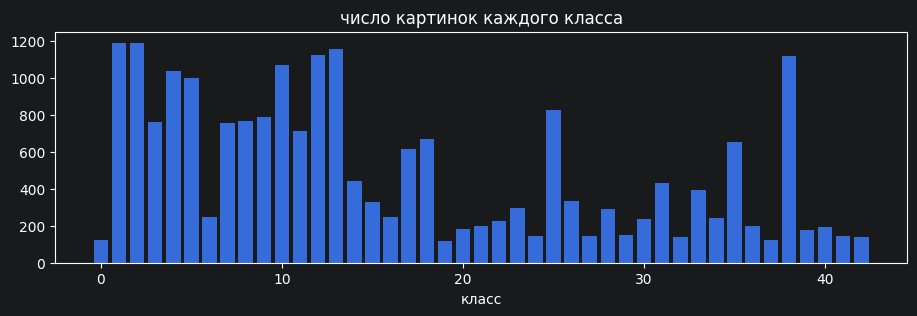

минимум в классе 118 максимум 1190


In [3]:
counts = torch.zeros(43)
for _, y in train_loader:
    for label in y:
        counts[label] += 1

plt.figure(figsize=(11, 3))
plt.bar(range(43), counts)
plt.title("число картинок каждого класса")
plt.xlabel("класс")
plt.show()
print("минимум в классе", int(counts.min()), "максимум", int(counts.max()))

## собираем MobileNetV2
внутри блока сначала увеличиваем число каналов через 1 на 1. потом делаем свертку 3 на 3 отдельно по каналам. в конце снова сжимаем каналы

если размер входа и выхода одинаковый то добавляем вход к выходу. это skip connection

In [4]:
class Block(nn.Module):
    def __init__(self, c_in, c_out, stride=1):
        super().__init__()
        hidden = c_in * 6
        self.layers = nn.Sequential(
            nn.Conv2d(c_in, hidden, 1, bias=False),
            nn.BatchNorm2d(hidden),
            nn.ReLU6(),
            nn.Conv2d(hidden, hidden, 3, stride, 1, groups=hidden, bias=False),
            nn.BatchNorm2d(hidden),
            nn.ReLU6(),
            nn.Conv2d(hidden, c_out, 1, bias=False),
            nn.BatchNorm2d(c_out)
        )
        self.skip = stride == 1 and c_in == c_out

    def forward(self, x):
        y = self.layers(x)
        return x + y if self.skip else y

делаем небольшую модель на 43 класса

In [5]:
class MobileNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1, bias=False),
            nn.BatchNorm2d(16),
            nn.ReLU6(),
            Block(16, 16),
            Block(16, 24, 2),
            Block(24, 24),
            Block(24, 32, 2),
            Block(32, 32),
            Block(32, 64, 2),
            Block(64, 64),
            nn.Conv2d(64, 128, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU6(),
            nn.AdaptiveAvgPool2d(1)
        )
        self.fc = nn.Linear(128, 43)

    def forward(self, x):
        x = self.features(x)
        return self.fc(torch.flatten(x, 1))

model = MobileNet().to(device)
print("параметров", sum(p.numel() for p in model.parameters() if p.requires_grad))

параметров 132955


пишем одну эпоху обучения и проверки

In [6]:
loss_fn = nn.CrossEntropyLoss()

def one_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    if training:
        model.train()
    else:
        model.eval()

    total_loss, correct, total = 0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        if training:
            optimizer.zero_grad()
        with torch.set_grad_enabled(training):
            out = model(x)
            loss = loss_fn(out, y)
            if training:
                loss.backward()
                optimizer.step()
        total_loss += loss.item() * len(y)
        correct += (out.argmax(1) == y).sum().item()
        total += len(y)
    return total_loss / total, correct / total

обучаем модель и сохраняем лучшую по val loss

In [7]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_loss = float("inf")

for epoch in range(8):
    train_loss, train_acc = one_epoch(model, train_loader, optimizer)
    val_loss, val_acc = one_epoch(model, val_loader)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)
    if val_loss < best_loss:
        best_loss = val_loss
        best_model = copy.deepcopy(model)
        best_epoch = epoch + 1
    print(f"эпоха {epoch + 1}  train {train_acc:.3f}  val {val_acc:.3f}")

print("лучшая эпоха", best_epoch)

эпоха 1  train 0.380  val 0.690
эпоха 2  train 0.853  val 0.949
эпоха 3  train 0.972  val 0.977
эпоха 4  train 0.991  val 0.983
эпоха 5  train 0.997  val 0.984
эпоха 6  train 0.999  val 0.990
эпоха 7  train 1.000  val 0.992
эпоха 8  train 1.000  val 0.994
лучшая эпоха 8


строим графики loss и accuracy

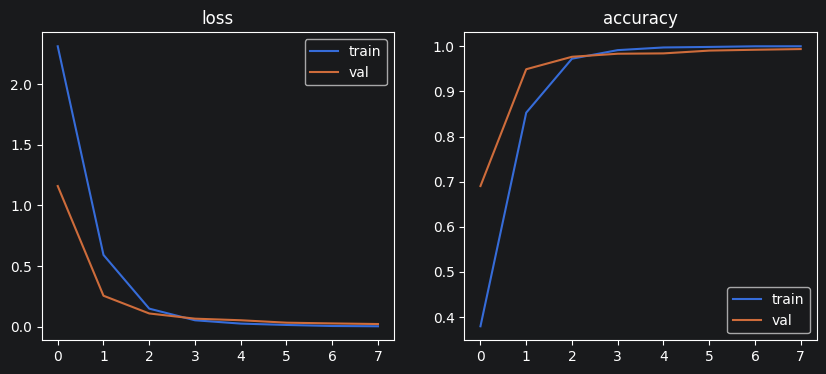

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for part in ["train", "val"]:
    ax[0].plot(history[part + "_loss"], label=part)
    ax[1].plot(history[part + "_acc"], label=part)
ax[0].set_title("loss")
ax[1].set_title("accuracy")
ax[0].legend()
ax[1].legend()
plt.show()

один раз проверяем лучшую модель на test

In [9]:
best_model.eval()
answers, predictions = [], []
test_loss = 0

with torch.no_grad():
    for x, y in test_loader:
        out = best_model(x.to(device))
        test_loss += loss_fn(out, y.to(device)).item() * len(y)
        answers.extend(y.tolist())
        predictions.extend(out.argmax(1).cpu().tolist())

print("test loss", round(test_loss / len(test), 4))

test loss 0.191


считаем accuracy macro F1 precision и recall

In [10]:
cm = torch.zeros(43, 43)
for a, b in zip(answers, predictions):
    cm[a, b] += 1

precision, recall, f1 = [], [], []
for i in range(43):
    p = cm[i, i].item() / max(cm[:, i].sum().item(), 1)
    r = cm[i, i].item() / max(cm[i].sum().item(), 1)
    precision.append(p)
    recall.append(r)
    f1.append(2 * p * r / (p + r) if p + r else 0)

accuracy = sum(cm[i, i].item() for i in range(43)) / len(test)
print("accuracy", round(accuracy, 4))
print("macro F1", round(sum(f1) / 43, 4))

accuracy 0.9424
macro F1 0.9097


показываем confusion matrix

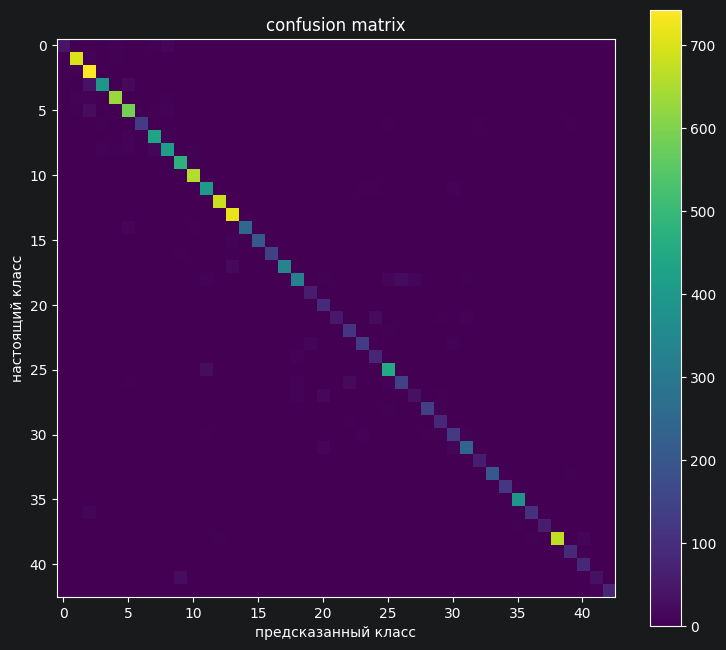

In [11]:
plt.figure(figsize=(9, 8))
plt.imshow(cm)
plt.colorbar()
plt.xlabel("предсказанный класс")
plt.ylabel("настоящий класс")
plt.title("confusion matrix")
plt.xticks(range(0, 43, 5))
plt.yticks(range(0, 43, 5))
plt.show()

показываем precision и recall по всем классам

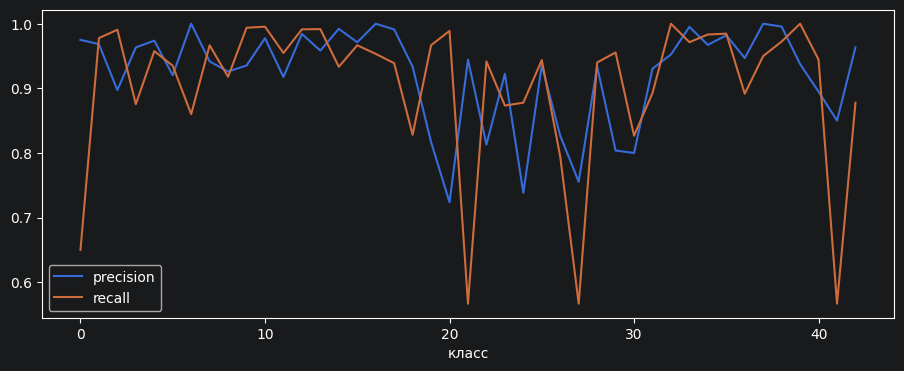

In [12]:
plt.figure(figsize=(11, 4))
plt.plot(range(43), precision, label="precision")
plt.plot(range(43), recall, label="recall")
plt.xlabel("класс")
plt.legend()
plt.show()

ищем какие классы модель чаще путает

In [13]:
errors = []
for i in range(43):
    for j in range(43):
        if i != j:
            errors.append((int(cm[i, j]), i, j))

for count, a, b in sorted(errors, reverse=True)[:5]:
    print("класс", a, "путает с", b, "случаев", count)

класс 3 путает с 2 случаев 35
класс 41 путает с 9 случаев 26
класс 25 путает с 11 случаев 25
класс 5 путает с 2 случаев 25
класс 21 путает с 24 случаев 23


## вывод
сделали уменьшенную MobileNetV2 и обучили ее распознавать дорожные знаки

главные идеи это расширение каналов, свертка по каждому каналу, сжатие без ReLU и skip connection. такая свертка требует меньше весов чем обычная

по графикам смотрим как менялись ошибка и точность. итоговые результаты берем только с test. по confusion matrix видно какие знаки модель путает чаще всего

в ходе работы была обучена модель MobileNetV2 для классификации дорожных знаков GTSRB. Точность на тестовой выборке составила 94,24%, а macro F1 — 0,9097. По матрице ошибок видно, что большинство изображений распознается правильно. Чаще всего модель путает похожие дорожные знаки. В целом модель показала хорошее качество классификации.